In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussian Mixture Models

In this assignment, you will be implementing Gaussian Mixture Models using Expectation Maximization algorithm.

1. Estimation Step
2. Maximization Step

In [7]:
from scipy.stats import multivariate_normal as mvn
from sklearn.cluster import KMeans

class GMM:
    """ Gaussian Mixture Model

    Parameters
    ----------
        C : int, Number of Gaussian components (clusters).
        n_runs : int, Number of EM iterations to run.

    """
    def __init__(self, C, n_runs):
        self.C = C # number of Guassians/clusters
        self.n_runs = n_runs

    def get_params(self):
        return (self.mu, self.pi, self.sigma)

    def calculate_mean_covariance(self, X, prediction):
        """Calculate means and covariance of different
            clusters from k-means prediction

        Parameters:
        ------------
        prediction: cluster labels from k-means

        X: N*d numpy array data points

        Returns:
        -------------
        intial_means: for E-step of EM algorithm

        intial_cov: for E-step of EM algorithm
        """
        d = X.shape[1]
        labels = np.unique(prediction)
        self.initial_means = np.zeros((self.C, d))
        self.initial_cov = np.zeros((self.C, d, d))
        self.initial_pi = np.zeros(self.C)

        counter=0
        for label in labels:
            ids = np.where(prediction == label) # returns indices
            self.initial_pi[counter] = len(ids[0]) / X.shape[0]
            self.initial_means[counter,:] = np.mean(X[ids], axis = 0)
            de_meaned = X[ids] - self.initial_means[counter,:]
            Nk = X[ids].shape[0] # number of data points in current gaussian
            self.initial_cov[counter,:, :] = np.dot(self.initial_pi[counter] * de_meaned.T, de_meaned) / Nk
            counter+=1
        assert np.isclose(np.sum(self.initial_pi), 1.0)


        return (self.initial_means, self.initial_cov, self.initial_pi)

    def _initialise_parameters(self, X):
        """Implement k-means to find starting
            parameter values.
            https://datascience.stackexchange.com/questions/11487/how-do-i-obtain-the-weight-and-variance-of-a-k-means-cluster
        Parameters:
        ------------
        X: numpy array of data points

        Returns:
        ----------
        tuple containing initial means and covariance

        _initial_means: numpy array: (C*d)

        _initial_cov: numpy array: (C,d*d)
        """
        kmeans = KMeans(n_clusters=self.C, init="k-means++", max_iter=500)
        kmeans.fit(X)
        return self.calculate_mean_covariance(X, kmeans.predict(X))

    def _expectation_step(self, X, pi, mu, sigma):
        """Performs E-step on GMM model
        Parameters:
        ------------
        X: (N x d), data points, m: no of features
        pi: (C), weights of mixture components
        mu: (C x d), mixture component means
        sigma: (C x d x d), mixture component covariance matrices
        Returns:
        ----------
        gamma: (N x C), probabilities of clusters for objects
        """
        N = X.shape[0]
        self.gamma = np.zeros((N, self.C))

        self.mu = mu
        self.pi = pi
        self.sigma = sigma

        # YOUR CODE HERE
        for i in range(N):
            probs = [
                self.pi[k] *
                mvn.pdf(X[i], mean=self.mu[k], cov=self.sigma[k])
                for k in range(self.C)
            ]
            total = sum(probs)

            for k in range(self.C):
                self.gamma[i, k] = probs[k] / total

        return self.gamma


    def _maximization_step(self, X, gamma):
        """Performs M-step of the GMM
        We need to update our priors, our means
        and our covariance matrix.
        Parameters:
        -----------
        X: (N x d), data
        gamma: (N x C), posterior distribution of lower bound
        Returns:
        ---------
        pi: (C)
        mu: (C x d)
        sigma: (C x d x d)
        """
        N = X.shape[0] # number of objects
        C = self.gamma.shape[1] # number of clusters
        d = X.shape[1] # dimension of each object

        # responsibilities for each gaussian
        # YOUR CODE START HERE
        Ns = np.sum(gamma, axis=0)
        self.pi = Ns / N # Fill the code here
        self.mu = np.array([np.sum(gamma[:, k][:, np.newaxis] * X, axis=0) / Ns[k] for k in range(C)]) # Fill the code here
        # YOUR CODE END HERE

        for c in range(C):
            x = X - self.mu[c, :] # (N x d)

            gamma_diag = np.diag(self.gamma[:,c])
            x_mu = np.matrix(x)
            gamma_diag = np.matrix(gamma_diag)

            sigma_c = x.T * gamma_diag * x
            self.sigma[c,:,:]= (sigma_c) / np.sum(self.gamma, axis = 0)[:,np.newaxis][c]

        return self.pi, self.mu, self.sigma


    def _compute_loss_function(self, X, pi, mu, sigma):
        """Computes lower bound loss function
        Parameters:
        -----------
        X: (N x d), data

        Returns:
        ---------
        pi: (C)
        mu: (C x d)
        sigma: (C x d x d)
        """
        N = X.shape[0]
        C = self.gamma.shape[1]
        self.loss = np.zeros((N, C))

        for c in range(C):
            dist = mvn(self.mu[c], self.sigma[c],allow_singular=True)
            self.loss[:,c] = self.gamma[:,c] * (np.log(self.pi[c]+0.00001)+dist.logpdf(X)-np.log(self.gamma[:,c]+0.000001))
        self.loss = np.sum(self.loss)
        return self.loss

    def fit(self, X):
        """Compute the E-step and M-step and
            Calculates the lowerbound

        Parameters:
        -----------
        X: (N x d), data

        Returns:
        ----------
        instance of GMM

        """

        d = X.shape[1]
        self.mu, self.sigma, self.pi =  self._initialise_parameters(X)

        for run in range(self.n_runs):
            self.gamma  = self._expectation_step(X, self.pi, self.mu, self.sigma)
            self.pi, self.mu, self.sigma = self._maximization_step(X, self.gamma)
            loss = self._compute_loss_function(X, self.pi, self.mu, self.sigma)

            if run % 10 == 0:
                print("Iteration: %d Loss: %0.6f" %(run, loss))
        return self

    def predict(self, X):
        """Returns predicted labels using Bayes Rule to
        Calculate the posterior distribution

        Parameters:
        -------------
        X: ?*d numpy array

        Returns:
        ----------
        labels: predicted cluster based on
        highest responsibility gamma.

        """
        labels = np.zeros((X.shape[0], self.C))

        for c in range(self.C):
            labels [:,c] = self.pi[c] * mvn.pdf(X, self.mu[c,:], self.sigma[c])
        labels  = labels .argmax(1)
        return labels

    def predict_proba(self, X):
        """Returns predicted labels

        Parameters:
        -------------
        X: N*d numpy array

        Returns:
        ----------
        labels: predicted cluster based on
        highest responsibility gamma.

        """
        post_proba = np.zeros((X.shape[0], self.C))

        for c in range(self.C):
            # Posterior Distribution using Bayes Rule, try and vectorise
            post_proba[:,c] = self.pi[c] * mvn.pdf(X, self.mu[c,:], self.sigma[c])

        return post_proba

## (a) Implement E-step

## (b) Implement M-step

## (c) Plot Clusters

- (i) Plot clusters with different iterations
- (ii) Plot clusters with different number of clusters

In [8]:
from sklearn import datasets

# Load training data
iris = datasets.load_iris()
train_data = iris.data[:,[0,1]]

In [9]:
from matplotlib.patches import Ellipse

# Helper function
def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draw an ellipse with a given position and covariance"""
    ax = ax or plt.gca()

    # Convert covariance to principal axes
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle = 0
        width, height = 2 * np.sqrt(covariance)

    # Draw the Ellipse
    for nsig in range(1, 4):
        ax.add_patch(Ellipse(position, nsig * width, nsig * height,
                             angle=angle, **kwargs))

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -270.770626


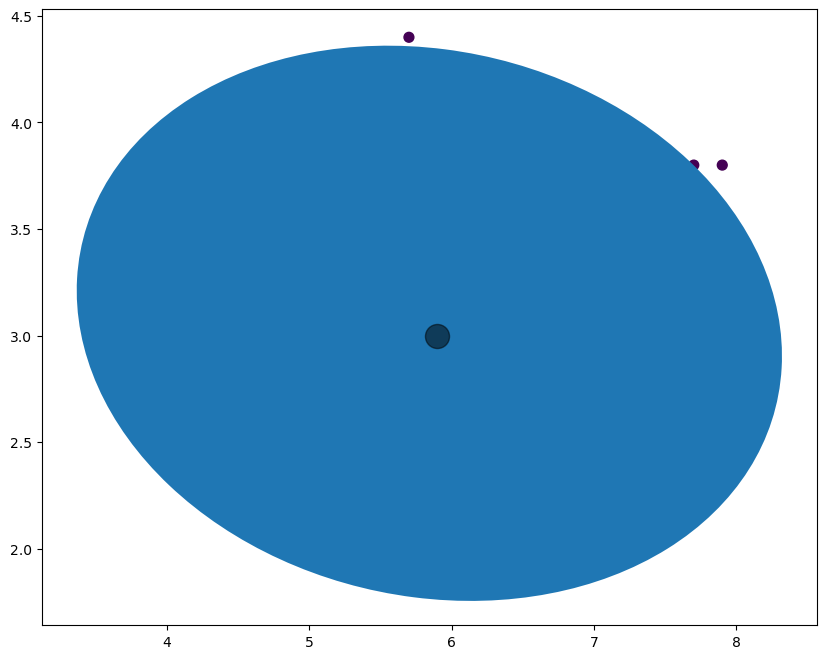

In [10]:
num_center = 1
num_runs = 1

model = GMM(num_center, n_runs = num_runs)

# Helper function

fitted_values = model.fit(train_data)
predicted_values = model.predict(train_data)

# # compute centers as point of highest density of distribution
centers = np.zeros((num_center,2))
for i in range(model.C):
    density = mvn(cov=model.sigma[i], mean=model.mu[i]).logpdf(train_data)
    centers[i, :] = train_data[np.argmax(density)]

plt.figure(figsize = (10,8))
plt.scatter(train_data[:, 0], iris.data[:, 1],c=predicted_values ,s=50, cmap='viridis', zorder=1)

plt.scatter(centers[:, 0], centers[:, 1],c='black', s=300, alpha=0.5, zorder=2);

for pos, covar, w in zip(model.mu, model.sigma, model.pi):
    draw_ellipse(pos, covar, alpha = w)

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -237.082857


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -237.082857


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -237.082857


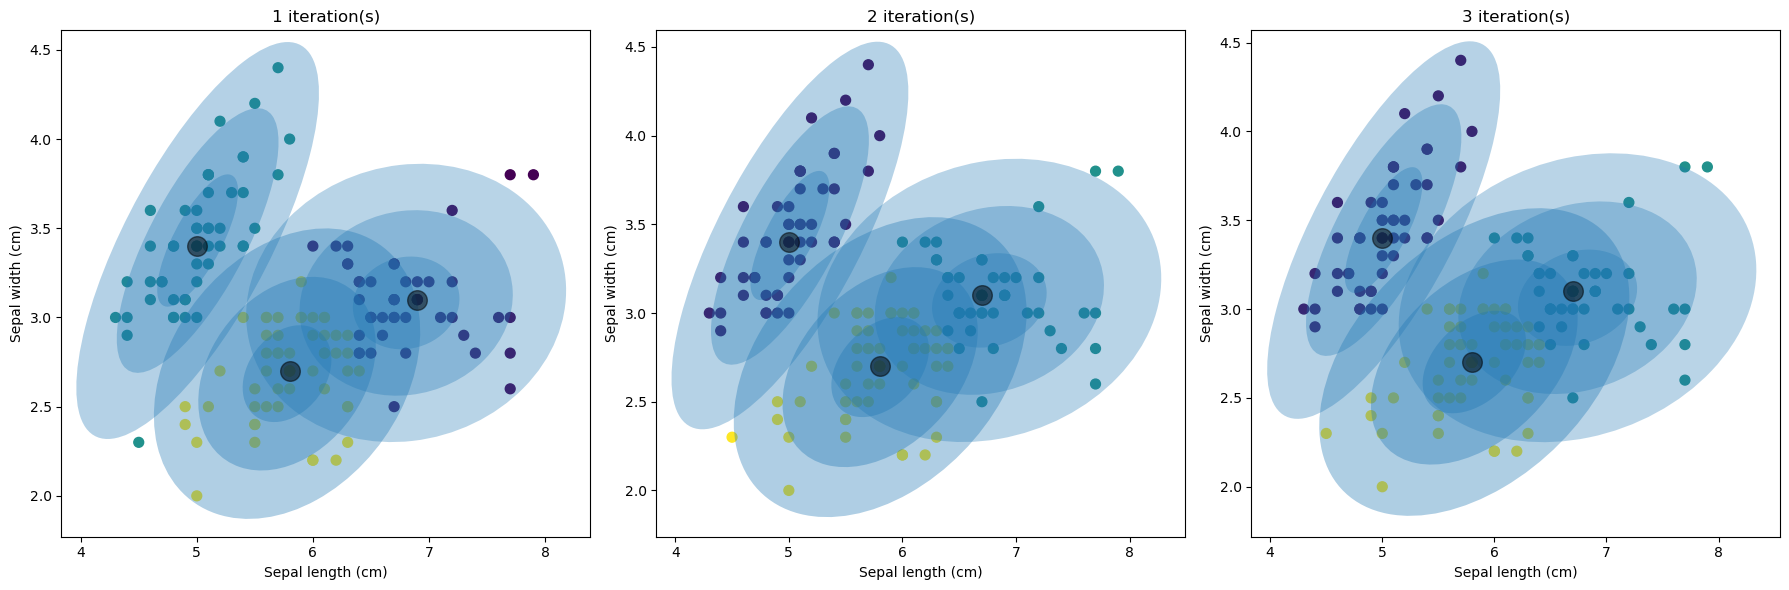

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, n_iter in enumerate([1, 2, 3]):
    ax = axes[idx]
    model = GMM(C=3, n_runs=n_iter)
    model.fit(train_data)
    pred = model.predict(train_data)
    
    centers = np.zeros((model.C, 2))
    for i in range(model.C):
        density = mvn(cov=model.sigma[i], mean=model.mu[i]).logpdf(train_data)
        centers[i, :] = train_data[np.argmax(density)]
    
    ax.scatter(train_data[:,0], train_data[:,1], c=pred, s=50, cmap='viridis', zorder=1)
    ax.scatter(centers[:,0], centers[:,1], c='black', s=200, alpha=0.5, zorder=2)
    
    for pos, covar, w in zip(model.mu, model.sigma, model.pi):
        draw_ellipse(pos, covar, ax=ax, alpha=w)
    
    ax.set_title(f"{n_iter} iteration(s)")
    ax.set_xlabel("Sepal length (cm)")
    ax.set_ylabel("Sepal width (cm)")

plt.tight_layout()
plt.show()

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -270.770626


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -250.903275


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -237.082857


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration: 0 Loss: -231.009561


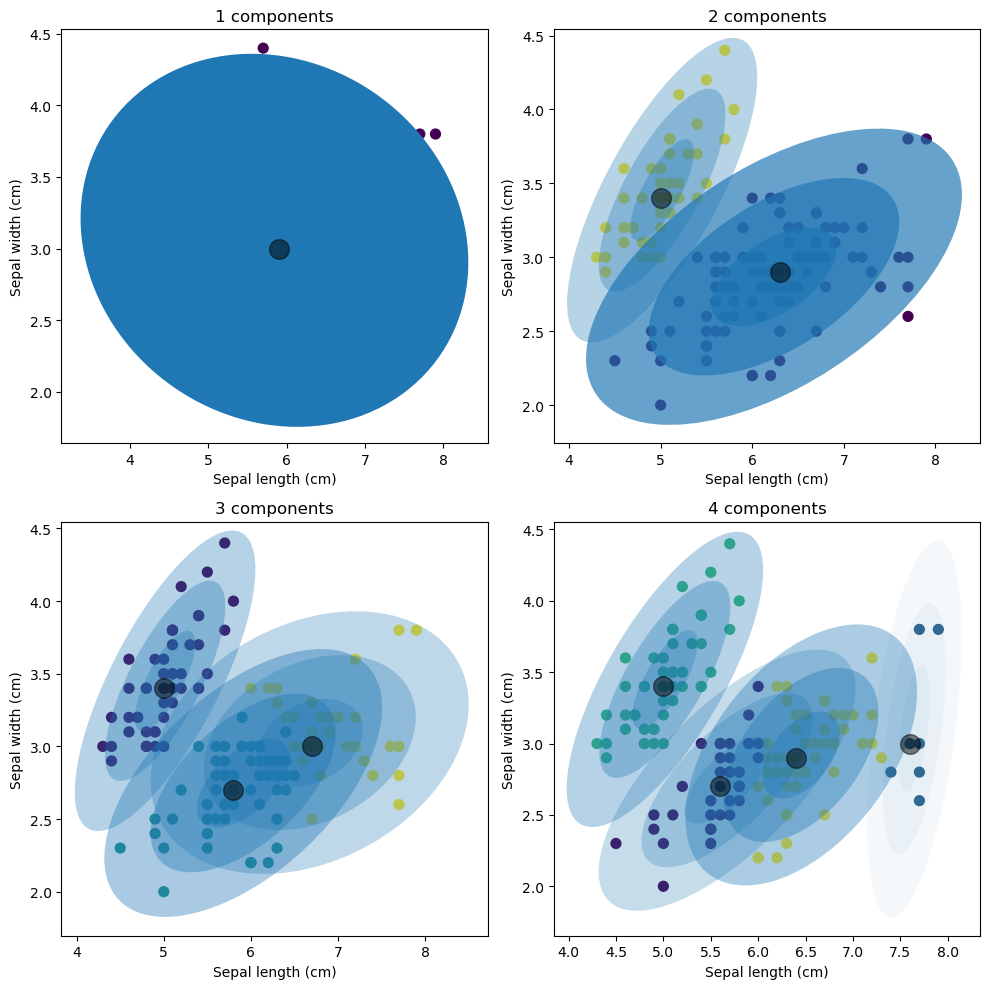

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for idx, C in enumerate([1, 2, 3, 4]):
    ax = axes[idx//2, idx%2]
    model = GMM(C=C, n_runs=10)
    model.fit(train_data)
    pred = model.predict(train_data)
    
    centers = np.zeros((model.C, 2))
    for i in range(model.C):
        density = mvn(cov=model.sigma[i], mean=model.mu[i]).logpdf(train_data)
        centers[i, :] = train_data[np.argmax(density)]
    
    ax.scatter(train_data[:,0], train_data[:,1], c=pred, s=50, cmap='viridis', zorder=1)
    ax.scatter(centers[:,0], centers[:,1], c='black', s=200, alpha=0.5, zorder=2)
    
    for pos, covar, w in zip(model.mu, model.sigma, model.pi):
        draw_ellipse(pos, covar, ax=ax, alpha=w)
    
    ax.set_title(f"{C} components")
    ax.set_xlabel("Sepal length (cm)")
    ax.set_ylabel("Sepal width (cm)")

plt.tight_layout()
plt.show()